# Sarcasm Detection Using BERT + BiLSTM + CNN 

This notebook trains a sarcasm classifier using a pretrained BERT encoder followed by BiLSTM and CNN layers.

Workflow:
1. Load and preprocess the dataset.
2. Tokenize comments with BERT.
3. Split data into training and testing sets.
4. Train the BERT + BiLSTM + CNN model with live progress.
5. Evaluate the model and predict sarcasm in new comments.



In [22]:
# Run this cell only if packages are missing.
# %pip install torch transformers pandas numpy scikit-learn matplotlib seaborn tqdm


## 2. Import libraries and configure the device

In [23]:
import os
import re
import random
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from tqdm.auto import tqdm

RANDOM_STATE = 42
MAX_LENGTH = 64
BATCH_SIZE = 16                 # bigger batches = much less noisy gradients
GRADIENT_ACCUMULATION_STEPS = 1
EPOCHS = 3
BERT_LR = 2e-5                  # pretrained BERT: small learning rate
HEAD_LR = 1e-3                  # new BiLSTM/CNN/dense layers: they need a much larger one
MAX_SAMPLES = 30_000            # random rows (set to None to use the full dataset)

def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", device)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
print("Mixed precision:", USE_AMP)
print("Batch size:", BATCH_SIZE, "| Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)


PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory: 4.0 GB
Mixed precision: True
Batch size: 16 | Gradient accumulation: 1


## 3. Load the dataset

In [24]:
DATA_PATH = "train-balanced-sarcasm.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the CSV file in the notebook folder "
        "or update DATA_PATH to its full path."
    )

df = pd.read_csv(DATA_PATH)
print("Original shape:", df.shape)
display(df.head())


Original shape: (1010826, 10)


,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...


In [25]:
# Take a RANDOM sample (the first rows of the file are not representative).
df = df[["label", "comment"]].dropna().copy()
if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df = df.sample(n=MAX_SAMPLES, random_state=RANDOM_STATE).copy()

df["label"] = df["label"].astype(int)

print("Working shape:", df.shape)
print(df["label"].value_counts())
display(df.head())


Working shape: (30000, 2)
label
0    15037
1    14963
Name: count, dtype: int64


,label,comment
355665,1,Yes and the buff it desperately needs
538060,0,Hilarious because i visited A2 one weekend las...
507644,0,Have you asked them what they want to eat?
519815,1,Because that worked out so well with the mater...
155398,1,But white people can't be discriminated against!


## 4. Text preprocessing

The old cleaning removed **spaces and punctuation**, gluing every comment into one word. Now the text is kept as written (only extra whitespace is tidied). `bert-base-uncased` lowercases on its own, and marks like `!`, `?` and quotes are useful sarcasm cues.

In [26]:
# Keep the text as written; only normalise whitespace.
df["comment"] = (
    df["comment"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Remove comments that are empty.
df = df[df["comment"].str.len() > 0].reset_index(drop=True)

print("Rows after cleaning:", len(df))
display(df.head(3))


Rows after cleaning: 30000


,label,comment
0,1,Yes and the buff it desperately needs
1,0,Hilarious because i visited A2 one weekend las...
2,0,Have you asked them what they want to eat?


## 5. Load the BERT tokenizer and tokenize comments

In [27]:
MODEL_NAME = "bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

# The tokenizer returns PyTorch tensors because return_tensors='pt'.
encoded = tokenizer(
    df["comment"].tolist(),
    max_length=MAX_LENGTH,
    truncation=True,
    padding="max_length",
    return_tensors="pt"
)

input_ids = encoded["input_ids"]
attention_masks = encoded["attention_mask"]
labels = torch.tensor(df["label"].values, dtype=torch.float32)

print("Input IDs shape:", input_ids.shape)
print("Attention mask shape:", attention_masks.shape)
print("Labels shape:", labels.shape)
print("Example tokens:", tokenizer.convert_ids_to_tokens(input_ids[0][:15]))


Input IDs shape: torch.Size([30000, 64])
Attention mask shape: torch.Size([30000, 64])
Labels shape: torch.Size([30000])
Example tokens: ['[CLS]', 'yes', 'and', 'the', 'buff', 'it', 'desperately', 'needs', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


## 6. Train-test split

In [28]:
indices = np.arange(len(df))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["label"].values
)

print("Training rows:", len(train_indices))
print("Testing rows:", len(test_indices))


Training rows: 24000
Testing rows: 6000


## 7. Create PyTorch datasets and data loaders

In [29]:
class SarcasmDataset(Dataset):
    def __init__(self, input_ids, attention_masks, labels, indices):
        self.input_ids = input_ids[indices]
        self.attention_masks = attention_masks[indices]
        self.labels = labels[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.input_ids[index],
            "attention_mask": self.attention_masks[index],
            "labels": self.labels[index]
        }

train_dataset = SarcasmDataset(input_ids, attention_masks, labels, train_indices)
test_dataset = SarcasmDataset(input_ids, attention_masks, labels, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=(device.type == "cuda"),
    num_workers=0
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda"),
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 1500
Testing batches: 375


## 8. Build the BERT + BiLSTM + CNN model

The model processes the **token sequence** rather than pooling it before the LSTM. This allows the BiLSTM and CNN to learn from token-level context.

Architecture:

`Input IDs + Attention Mask → BERT → Dense → BiLSTM → CNN → Masked Mean Pooling → Dense → Sigmoid classification`

The model returns raw logits. `BCEWithLogitsLoss` applies the numerically stable sigmoid-plus-binary-cross-entropy calculation during training.


In [30]:
class HierarchicalBERT(nn.Module):
    def __init__(
        self,
        bert_model,
        lstm_units=128,
        cnn_filters=128,
        dense_units=128,
        dropout=0.3
    ):
        super().__init__()

        self.bert = bert_model
        hidden_size = self.bert.config.hidden_size

        self.dense_sentence = nn.Linear(hidden_size, hidden_size)

        self.bilstm_encoder = nn.LSTM(
            input_size=hidden_size,
            hidden_size=lstm_units,
            batch_first=True,
            bidirectional=True
        )

        self.conv = nn.Conv1d(
            in_channels=lstm_units * 2,
            out_channels=cnn_filters,
            kernel_size=3,
            padding=1
        )

        self.dense_df = nn.Linear(cnn_filters, dense_units)
        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(dense_units, 1)

    def forward(self, input_ids, attention_mask):
        # BERT output: (batch_size, sequence_length, hidden_size)
        bert_output = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state

        sentence_encoded = torch.relu(self.dense_sentence(bert_output))

        # BiLSTM works across the token sequence.
        context_encoded, _ = self.bilstm_encoder(sentence_encoded)

        # Conv1d expects (batch_size, channels, sequence_length).
        conv_input = context_encoded.transpose(1, 2)
        conv_output = torch.relu(self.conv(conv_input))

        # Mask out padding token positions before pooling.
        mask = attention_mask.unsqueeze(1).to(conv_output.dtype)
        conv_output = conv_output * mask

        # Mean pooling over non-padding token positions.
        summed = conv_output.sum(dim=2)
        counts = mask.sum(dim=2).clamp(min=1.0)
        pooled_output = summed / counts

        dense_output = torch.relu(self.dense_df(pooled_output))
        dense_output = self.dropout(dense_output)

        # Return logits (no sigmoid here).
        return self.output_layer(dense_output).squeeze(1)


## 9. Load pretrained BERT and initialize the classifier

In [31]:
bert_model = BertModel.from_pretrained(MODEL_NAME)

model = HierarchicalBERT(
    bert_model=bert_model,
    lstm_units=128,
    cnn_filters=128,
    dense_units=128,
    dropout=0.3
).to(device)

print("Model loaded on:", device)


Model loaded on: cuda


## 10. Define loss, optimizer, and learning-rate scheduler

In [32]:
# Balance the classes (about 63% not sarcastic / 37% sarcastic).
train_labels = labels[train_indices]
pos_weight = (train_labels == 0).sum() / (train_labels == 1).sum()
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

# Separate learning rates: small for pretrained BERT, large for the new layers.
bert_param_ids = {id(p) for p in model.bert.parameters()}
bert_params = list(model.bert.parameters())
head_params = [p for p in model.parameters() if id(p) not in bert_param_ids]

optimizer = torch.optim.AdamW(
    [
        {"params": bert_params, "lr": BERT_LR},
        {"params": head_params, "lr": HEAD_LR},
    ],
    weight_decay=0.01
)

# Scheduler steps count optimizer updates, not individual mini-batches.
updates_per_epoch = math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS)
total_training_steps = updates_per_epoch * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.06 * total_training_steps),
    num_training_steps=total_training_steps
)

# Mixed precision reduces VRAM usage on CUDA GPUs.
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("pos_weight:", round(pos_weight.item(), 3))


pos_weight: 1.005


## 11. Train the model

In [33]:
def evaluate_model(loader):
    model.eval()
    probs, labs = [], []
    with torch.no_grad():
        for batch in loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(ids, mask)
            probs.extend(torch.sigmoid(logits.float()).cpu().tolist())
            labs.extend(batch["labels"].tolist())
    probs, labs = np.array(probs), np.array(labs)
    preds = (probs >= 0.5).astype(int)
    return f1_score(labs, preds, average="macro"), accuracy_score(labs, preds), probs


training_history = []
best_f1 = -1.0
best_state = None

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    progress_bar = tqdm(
        enumerate(train_loader, start=1),
        total=len(train_loader),
        desc=f"Epoch {epoch + 1}/{EPOCHS}",
        unit="batch",
        dynamic_ncols=True
    )

    for step, batch in progress_bar:
        batch_input_ids = batch["input_ids"].to(device, non_blocking=True)
        batch_attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        batch_labels = batch["labels"].to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(batch_input_ids, batch_attention_mask)
            loss = criterion(logits, batch_labels)
            scaled_loss = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(scaled_loss).backward()
        running_loss += loss.item()

        if step % GRADIENT_ACCUMULATION_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        progress_bar.set_postfix(
            batch_loss=f"{loss.item():.4f}",
            avg_loss=f"{running_loss / step:.4f}"
        )

    average_loss = running_loss / len(train_loader)
    training_history.append(average_loss)

    # Check after every epoch that the model is really learning.
    f1, acc, probs = evaluate_model(test_loader)
    print(f"Epoch {epoch + 1}/{EPOCHS} | loss {average_loss:.4f} | test acc {acc:.4f} | "
          f"macro-F1 {f1:.4f} | probability range {probs.min():.2f}-{probs.max():.2f}")
    if probs.max() - probs.min() < 0.2:
        print("WARNING: predictions are almost constant, the model is not learning yet.")

    if f1 > best_f1:
        best_f1 = f1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

# Continue with the best epoch.
model.load_state_dict(best_state)
print(f"Training complete. Best macro-F1: {best_f1:.4f}")


Epoch 1/3: 100%|██████████| 1500/1500 [03:28<00:00,  7.19batch/s, avg_loss=0.5962, batch_loss=0.3950]


Epoch 1/3 | loss 0.5962 | test acc 0.7238 | macro-F1 0.7203 | probability range 0.12-0.92


Epoch 2/3: 100%|██████████| 1500/1500 [03:34<00:00,  6.99batch/s, avg_loss=0.4522, batch_loss=0.5882]


Epoch 2/3 | loss 0.4522 | test acc 0.7285 | macro-F1 0.7285 | probability range 0.04-0.97


Epoch 3/3: 100%|██████████| 1500/1500 [03:35<00:00,  6.96batch/s, avg_loss=0.3110, batch_loss=0.0981]


Epoch 3/3 | loss 0.3110 | test acc 0.7265 | macro-F1 0.7264 | probability range 0.01-0.99
Training complete. Best macro-F1: 0.7285


## 12. Evaluate the model

Evaluating: 100%|██████████| 375/375 [00:10<00:00, 35.04batch/s]


Test Accuracy: 0.7285

Classification Report:
              precision    recall  f1-score   support

         0.0     0.7339    0.7190    0.7264      3007
         1.0     0.7233    0.7381    0.7306      2993

    accuracy                         0.7285      6000
   macro avg     0.7286    0.7285    0.7285      6000
weighted avg     0.7286    0.7285    0.7285      6000



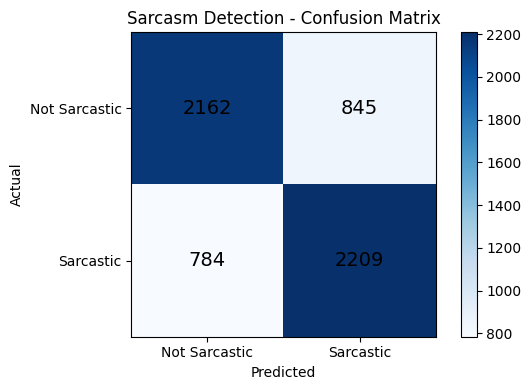

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():
    evaluation_bar = tqdm(test_loader, desc="Evaluating", unit="batch")

    for batch in evaluation_bar:
        batch_input_ids = batch["input_ids"].to(device)
        batch_attention_mask = batch["attention_mask"].to(device)
        batch_labels = batch["labels"]

        with torch.amp.autocast(
            device_type=device.type, dtype=torch.float16, enabled=USE_AMP
        ):
            logits = model(batch_input_ids, batch_attention_mask)

        probabilities = torch.sigmoid(logits.float())
        predictions = (probabilities >= 0.5).long()

        all_probabilities.extend(probabilities.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch_labels.numpy())

# Evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_predictions, digits=4))

# Confusion Matrix Visualization
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0, 1], ["Not Sarcastic", "Sarcastic"])
plt.yticks([0, 1], ["Not Sarcastic", "Sarcastic"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sarcasm Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

## 13. Predict sarcasm in a new comment

In [35]:
def predict_sarcasm(text):
    model.eval()

    # Same cleaning as training: keep the text, only normalise whitespace.
    cleaned_text = re.sub(r"\s+", " ", str(text)).strip()

    inputs = tokenizer(
        cleaned_text,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        logits = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        probability = torch.sigmoid(logits).item()

    prediction = "Sarcastic" if probability >= 0.5 else "Not sarcastic"
    return prediction, probability

# Examples
for text in [
    "Oh great, another meeting. Just what I needed.",
    "Wow, you're SO smart. Thanks for explaining my own job to me.",
    "Thanks for the help, I really appreciate it.",
    "The train leaves at 6 pm from platform 3.",
]:
    prediction, probability = predict_sarcasm(text)
    print(f"{prediction:14s} {probability:.4f}  |  {text}")


Sarcastic      0.8406  |  Oh great, another meeting. Just what I needed.
Sarcastic      0.9320  |  Wow, you're SO smart. Thanks for explaining my own job to me.
Sarcastic      0.7039  |  Thanks for the help, I really appreciate it.
Not sarcastic  0.0844  |  The train leaves at 6 pm from platform 3.


## 14. Save the trained model

In [36]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "model_name": MODEL_NAME,
        "max_length": MAX_LENGTH,
        "lstm_units": 128,
        "cnn_filters": 128,
        "dense_units": 128
    },
    "sarcasm_bert_pytorch.pth"
)

tokenizer.save_pretrained("sarcasm_bert_tokenizer")

print("Model and tokenizer saved.")


Model and tokenizer saved.
